# 04_model_lgbm.ipynb

## 목차

### 1. 환경 세팅 및 데이터 로드
- 1-1. 필수 라이브러리 임포트
- 1-2. 전처리 완료 데이터 로드 (`hnm_churn_processed.csv`)
- 1-3. 데이터 무결성 확인

### 2. 데이터셋 분할
- 2-1. 독립변수 X, 종속변수 y 정의
- 2-2. Train / Validation 8:2 Stratified Split
- 2-3. 분할 후 클래스 비율 확인

### 3. 베이스라인 모델 학습
- 3-1. 기본 파라미터로 학습
- 3-2. 베이스라인 성능 측정 (Accuracy, AUC-ROC)

### 4. 하이퍼파라미터 튜닝
- 4-1. 튜닝 대상 파라미터 정의
- 4-2. GridSearchCV 실행
- 4-3. 최적 파라미터 확인

### 5. 최종 모델 학습 및 평가
- 5-1. 최적 파라미터로 최종 학습 (Early Stopping 적용)
- 5-2. Accuracy, AUC-ROC, F1-Score
- 5-3. Confusion Matrix
- 5-4. ROC Curve

### 6. 피처 중요도 분석
- 6-1. 피처 중요도 시각화
- 6-2. EDA 결과와 교차 해석

### 7. 결과 저장
- 7-1. 모델 성능 결과 저장 (`results/lgbm_result.csv`)

## 1. 환경 세팅 및 데이터 로드

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import time
import os

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    accuracy_score, roc_auc_score, f1_score,
    confusion_matrix, roc_curve, classification_report
)

plt.rc('font', family='Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')
pd.options.display.float_format = '{:.4f}'.format

print('라이브러리 임포트 완료')

라이브러리 임포트 완료


In [2]:
# 1-2. 전처리 완료 데이터 로드
df = pd.read_csv('./data/hnm_churn_processed.csv')

print(f'데이터 shape: {df.shape}')
print(f'결측치 합계: {df.isnull().sum().sum()}')

데이터 shape: (1143652, 45)
결측치 합계: 330842


In [3]:
# 1-3. 데이터 무결성 확인
print('--- 컬럼 목록 ---')
print(list(df.columns))
print(f'\n--- dtypes ---')
print(df.dtypes.value_counts())

--- 컬럼 목록 ---
['churn', 'frequency', 'price_mean', 'price_sum', 'price_max', 'recency', 'frequency_last_90d', 'frequency_last_180d', 'avg_purchase_interval', 'std_purchase_interval', 'unique_articles', 'unique_product_groups', 'FN', 'Active', 'age', 'club_member_status_ACTIVE', 'club_member_status_LEFT CLUB', 'club_member_status_PRE-CREATE', 'club_member_status_UNKNOWN', 'fashion_news_frequency_Monthly', 'fashion_news_frequency_NONE', 'fashion_news_frequency_Regularly', 'fashion_news_frequency_UNKNOWN', 'index_group_name_Baby/Children', 'index_group_name_Divided', 'index_group_name_Ladieswear', 'index_group_name_Menswear', 'index_group_name_Sport', 'product_group_name_Accessories', 'product_group_name_Bags', 'product_group_name_Cosmetic', 'product_group_name_Furniture', 'product_group_name_Garment Full body', 'product_group_name_Garment Lower body', 'product_group_name_Garment Upper body', 'product_group_name_Garment and Shoe care', 'product_group_name_Interior textile', 'product_group

## 2. 데이터셋 분할

In [4]:
# 2. 분할 데이터 로드
# 03_preprocessing에서 저장한 분할 데이터를 불러옵니다.
# random_state=42 Stratified Split 결과와 동일합니다.
X_train = pd.read_csv('./data/X_train.csv')
X_val   = pd.read_csv('./data/X_val.csv')
y_train = pd.read_csv('./data/y_train.csv').squeeze()
y_val   = pd.read_csv('./data/y_val.csv').squeeze()

print(f'X_train: {X_train.shape}, X_val: {X_val.shape}')
print(f'y_train 이탈률: {y_train.mean():.4f}')
print(f'y_val   이탈률: {y_val.mean():.4f}')

X_train: (914921, 44), X_val: (228731, 44)
y_train 이탈률: 0.5002
y_val   이탈률: 0.5002


## 3. 베이스라인 모델 학습

In [5]:
# 3-1. 기본 파라미터로 베이스라인 학습
baseline_model = lgb.LGBMClassifier(
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

start = time.time()
baseline_model.fit(X_train, y_train)
baseline_time = time.time() - start

# 3-2. 베이스라인 성능 측정
baseline_pred = baseline_model.predict(X_val)
baseline_proba = baseline_model.predict_proba(X_val)[:, 1]

baseline_acc = accuracy_score(y_val, baseline_pred)
baseline_auc = roc_auc_score(y_val, baseline_proba)
baseline_f1  = f1_score(y_val, baseline_pred)

print('--- LightGBM 베이스라인 성능 ---')
print(f'Accuracy : {baseline_acc:.4f}')
print(f'AUC-ROC  : {baseline_auc:.4f}')
print(f'F1-Score : {baseline_f1:.4f}')
print(f'학습 시간 : {baseline_time:.1f}초')

--- LightGBM 베이스라인 성능 ---
Accuracy : 0.7688
AUC-ROC  : 0.8476
F1-Score : 0.7715
학습 시간 : 5.6초


## 4. 하이퍼파라미터 튜닝

In [6]:
# 4-1. 튜닝 대상 파라미터 정의
# 전체 데이터가 크므로 범위를 좁게 설정해 탐색 시간을 줄입니다.
param_grid = {
    'num_leaves'       : [31, 63, 127],
    'max_depth'        : [-1, 10, 20],
    'learning_rate'    : [0.05, 0.1],
    'n_estimators'     : [200, 300],
    'subsample'        : [0.7, 0.9],
    'colsample_bytree' : [0.7, 0.9]
}

# 4-2. GridSearchCV 실행
# cv=3, scoring='roc_auc' 기준으로 최적 파라미터 탐색
lgbm_base = lgb.LGBMClassifier(random_state=42, n_jobs=-1, verbose=-1)

grid_search = GridSearchCV(
    estimator=lgbm_base,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

# 4-3. 최적 파라미터 확인
print('--- 최적 파라미터 ---')
print(grid_search.best_params_)
print(f'CV 최고 AUC: {grid_search.best_score_:.4f}')

Fitting 3 folds for each of 144 candidates, totalling 432 fits
--- 최적 파라미터 ---
{'colsample_bytree': 0.7, 'learning_rate': 0.05, 'max_depth': 10, 'n_estimators': 300, 'num_leaves': 127, 'subsample': 0.7}
CV 최고 AUC: 0.8479


## 5. 최종 모델 학습 및 평가

In [7]:
# 5-1. 최적 파라미터로 최종 학습 (Early Stopping 적용)
best_params = grid_search.best_params_

final_model = lgb.LGBMClassifier(
    **best_params,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

start = time.time()
final_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False),
               lgb.log_evaluation(period=-1)]
)
train_time = time.time() - start

print(f'최종 학습 완료 ({train_time:.1f}초)')

최종 학습 완료 (33.4초)


In [8]:
# 5-2. 최종 성능 측정
y_pred  = final_model.predict(X_val)
y_proba = final_model.predict_proba(X_val)[:, 1]

final_acc = accuracy_score(y_val, y_pred)
final_auc = roc_auc_score(y_val, y_proba)
final_f1  = f1_score(y_val, y_pred)

print('--- LightGBM 최종 성능 ---')
print(f'Accuracy : {final_acc:.4f}')
print(f'AUC-ROC  : {final_auc:.4f}')
print(f'F1-Score : {final_f1:.4f}')
print(f'학습 시간 : {train_time:.1f}초')
print()
print(classification_report(y_val, y_pred, target_names=['유지(0)', '이탈(1)']))

--- LightGBM 최종 성능 ---
Accuracy : 0.7691
AUC-ROC  : 0.8487
F1-Score : 0.7724
학습 시간 : 33.4초

              precision    recall  f1-score   support

       유지(0)       0.78      0.76      0.77    114320
       이탈(1)       0.76      0.78      0.77    114411

    accuracy                           0.77    228731
   macro avg       0.77      0.77      0.77    228731
weighted avg       0.77      0.77      0.77    228731



c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) Arial.
  fig.canvas.draw()
c:\Users\09048\2026project\hnm_churn\venv\Lib\site-packages\seaborn\utils.py:61: UserWarning: Glyph 53448 (\N{HANGUL SYLLABLE TAL}) missing from font(s) Arial.
  fig.canvas.draw()
C:\Users\09048\AppData\Local\Temp\ipykernel_16480\3827873138.py:11: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\09048\AppData\Local\Temp\ipykernel_16480\3827873138.py:11: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG

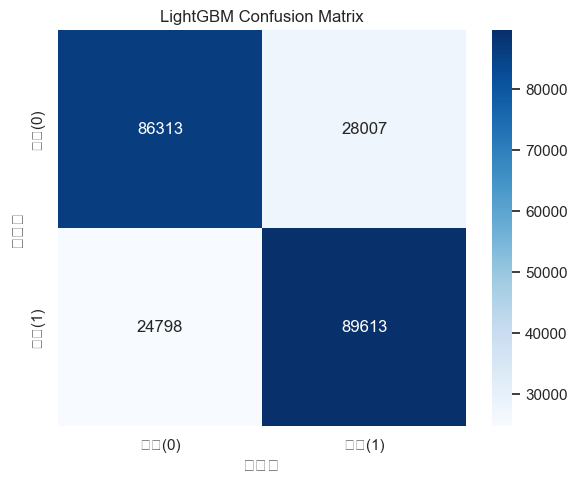

In [9]:
# 5-3. Confusion Matrix
cm = confusion_matrix(y_val, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['유지(0)', '이탈(1)'],
            yticklabels=['유지(0)', '이탈(1)'])
plt.title('LightGBM Confusion Matrix')
plt.ylabel('실제값')
plt.xlabel('예측값')
plt.tight_layout()
plt.show()

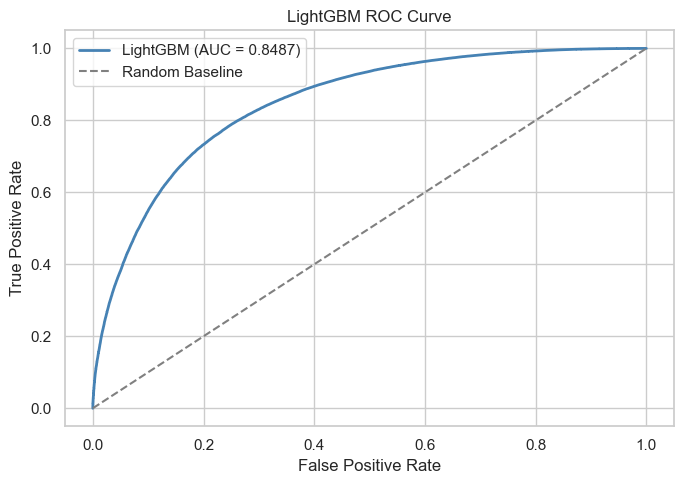

In [10]:
# 5-4. ROC Curve
fpr, tpr, _ = roc_curve(y_val, y_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'LightGBM (AUC = {final_auc:.4f})', color='steelblue', lw=2)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random Baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('LightGBM ROC Curve')
plt.legend()
plt.tight_layout()
plt.show()

## 6. 피처 중요도 분석

C:\Users\09048\AppData\Local\Temp\ipykernel_16480\2753666433.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='importance', y='feature', data=importance_df, palette='Blues_r')


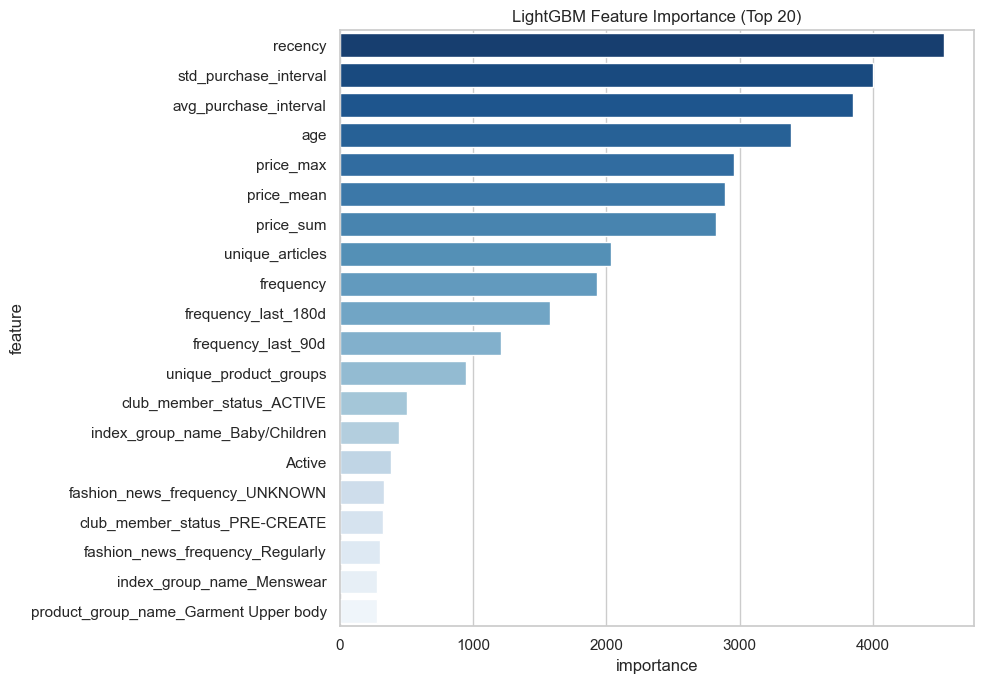

In [11]:
# 6-1. 피처 중요도 시각화 (상위 20개)
importance_df = pd.DataFrame({
    'feature'   : X_train.columns,
    'importance': final_model.feature_importances_
}).sort_values('importance', ascending=False).head(20)

plt.figure(figsize=(10, 7))
sns.barplot(x='importance', y='feature', data=importance_df, palette='Blues_r')
plt.title('LightGBM Feature Importance (Top 20)')
plt.tight_layout()
plt.show()

In [12]:
# 6-2. EDA 결과와 교차 해석
# EDA에서 이탈과 상관관계가 높았던 피처: recency, unique_product_groups, unique_articles, frequency
# 모델 피처 중요도 1~5위 확인 후 EDA 결과와 일치 여부 검토

print('--- 피처 중요도 Top 10 ---')
print(importance_df[['feature', 'importance']].head(10).to_string(index=False))

print()
print('--- EDA 상관관계 Top 5 (참고) ---')
print('recency                : 0.4812')
print('unique_product_groups  : -0.4695')
print('unique_articles        : -0.3768')
print('frequency              : -0.3587')
print('frequency_last_180d    : -0.3542')

--- 피처 중요도 Top 10 ---
              feature  importance
              recency        4532
std_purchase_interval        3998
avg_purchase_interval        3847
                  age        3389
            price_max        2958
           price_mean        2893
            price_sum        2823
      unique_articles        2036
            frequency        1926
  frequency_last_180d        1576

--- EDA 상관관계 Top 5 (참고) ---
recency                : 0.4812
unique_product_groups  : -0.4695
unique_articles        : -0.3768
frequency              : -0.3587
frequency_last_180d    : -0.3542


## 7. 결과 저장

In [13]:
# 7-1. 모델 성능 결과 저장
os.makedirs('./results', exist_ok=True)

result = pd.DataFrame([{
    'model'     : 'LightGBM',
    'accuracy'  : round(final_acc, 4),
    'auc_roc'   : round(final_auc, 4),
    'f1_score'  : round(final_f1, 4),
    'train_time': round(train_time, 1)
}])

result.to_csv('./results/lgbm_result.csv', index=False)

print('결과 저장 완료')
print(result.to_string(index=False))

결과 저장 완료
   model  accuracy  auc_roc  f1_score  train_time
LightGBM    0.7691   0.8487    0.7724     33.4000
